# Expected shortfall backtests: Acerbi-Szekely with simulated critical values, Du-Escanciano and McNeil-Frey

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 03 of this topic (the exceedance backtests)
- **Reading time:** about 45 minutes

**Question:** When the losses beyond the VaR are larger than the forecast expected shortfall, which test of the crisis year sees it: the Acerbi-Szekely statistic, the Du-Escanciano tests or the McNeil-Frey residuals?

## Objectives

By the end of this notebook you can:

- explain why a count of VaR exceedances cannot test an expected shortfall, and what the Acerbi-Szekely statistics $Z_1$ and $Z_2$ measure instead;
- compute $Z_2$ by hand from losses, VaR and ES for the 14 models of the 2008 crisis that forecast an ES;
- say what the engine asks the caller to supply to get a critical value, which null Contraste supplies, and why the critical values differ from model to model;
- compare each model's simulated critical value with the published reference point of $-0.70$ and $-1.8$, and say what that reference is and is not;
- run the Du-Escanciano and McNeil-Frey tests on a model whose predictive distribution is known, and read what each adds to $Z_2$.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools, print the versions they run with, make the pipeline's case code importable and name the
# lights
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The ES tests need the realised loss of every day, so the notebook works on the two windows of case C11 that commit it: `fx-2008` (the euro against the dollar, 251 days) and `rates-2022` (a 10-year Treasury position, 249 days), both built on `mirror-allowed` series. For each of the 17 models and each tail level the files hold the VaR and the ES (positive loss numbers) and, for the models that forecast an ES, the committed Acerbi-Szekely result with the histogram of its simulated null. `equity-2007-09` is read for its committed rows only: its returns are derived-only.

Three rungs do not forecast an ES (`cf-rolling`, `caviar-sav`, `caviar-as`), so the ES tests do not apply to them and the engine would return `not_evaluated`; the notebook skips them. The next cell loads the files and lists which models have an ES.

In [2]:
# Load the two windows that commit the realised losses and list the models that forecast an ES
C11 = ROOT / "data" / "derived" / "C11"
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in ("fx-2008", "rates-2022")}
fx = docs["fx-2008"]["outputs"]
models = {m["model_id"]: m for m in fx["models"]}
with_es = [mid for mid, m in models.items() if all(lv["es_status"] == "forecast" for lv in m["by_level"])]
loss = np.array(fx["grid"]["realised_loss"]["loss"])
print("models with an ES:", len(with_es), "of", len(models))
print("without an ES:", [mid for mid in models if mid not in with_es])
print("fx-2008: realised losses", loss.size, "| tail levels", [lv["alpha"] for lv in fx["levels"]])

models with an ES: 14 of 17
without an ES: ['cf-rolling', 'caviar-sav', 'caviar-as']
fx-2008: realised losses 251 | tail levels [0.01, 0.025]


## Method

### Step 1: why ES needs its own test, and the statistics $Z_1$ and $Z_2$

The expected shortfall is a statement about **how large** the losses are when the VaR is exceeded. The number of exceedances says nothing about their size: two models with the same VaR and the same count can have very different ES, and only one of them is right. Acerbi and Szekely (2014) test the ES with statistics built from the size of the loss on the exceedance days relative to the forecast ES. With $X_t = -\text{loss}_t$, $I_t = \mathbb 1\{\text{loss}_t > \text{VaR}_t\}$ and $N_T = \sum_t I_t$:

$$Z_1 = \frac{1}{N_T}\sum_{t=1}^{T}\frac{X_t\,I_t}{\mathrm{ES}_t} + 1, \qquad Z_2 = \sum_{t=1}^{T}\frac{X_t\,I_t}{T\,\alpha\,\mathrm{ES}_t} + 1$$

$Z_1$ averages, over the exceedance days only, the ratio of the realised loss to the forecast ES: it is 0 when the losses are, on average, as large as the ES says, and negative when they are larger. $Z_2$ replaces $N_T$ by the expected count $T\alpha$, so it also penalises a **wrong number** of exceedances. Both have expectation 0 under the null that the forecasts are right, and both are negative when risk is underestimated. The cell computes both by hand for every model with an ES, at both levels, and draws the $Z_2$ of every model.

model        alpha exceed.        Z1        Z2
hs-250       0.010      10   -0.0691   -3.2592
hs-250       0.025      13   -0.1350   -1.3513
dn-rolling   0.010      23   -0.2444  -10.4033
dn-rolling   0.025      35   -0.2394   -5.9131
ewma         0.010       3   -0.1242   -0.3437
ewma         0.025       8   -0.0323   -0.3160
garch-t      0.010       3   -0.0402   -0.2433
garch-t      0.025       7   -0.0117   -0.1286


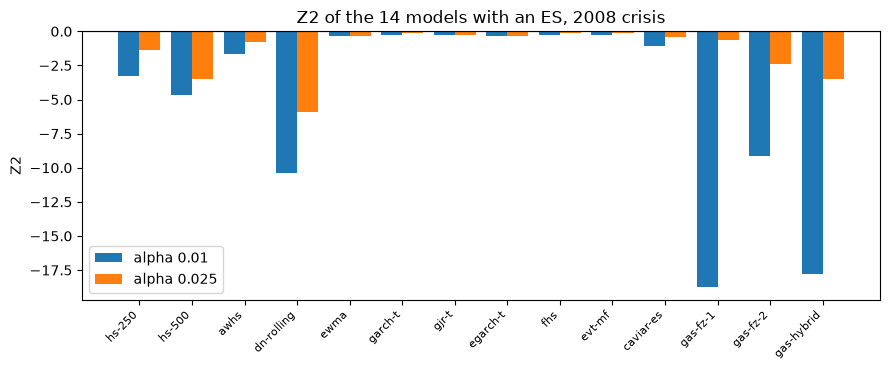

In [3]:
# Z1 and Z2 by hand from the losses, VaR and ES of every model with an ES, and the Z2 of each model drawn
by_hand = {}
for mid in with_es:
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        exceed = loss > var
        ratio = loss[exceed] / es[exceed]
        z1 = 1.0 - ratio.mean() if exceed.any() else float("nan")
        by_hand[(mid, alpha)] = (int(exceed.sum()), z1, 1.0 - ratio.sum() / (loss.size * alpha))
print(f"{'model':11s} {'alpha':>6s} {'exceed.':>7s} {'Z1':>9s} {'Z2':>9s}")
for mid in ("hs-250", "dn-rolling", "ewma", "garch-t"):
    for alpha in (0.01, 0.025):
        n_exceed, z1, z2 = by_hand[(mid, alpha)]
        print(f"{mid:11s} {alpha:6.3f} {n_exceed:7d} {z1:9.4f} {z2:9.4f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
for shift, alpha in ((-0.2, 0.01), (0.2, 0.025)):
    heights = [by_hand[(mid, alpha)][2] for mid in with_es]
    ax.bar(np.arange(len(with_es)) + shift, heights, width=0.4, label=f"alpha {alpha}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(np.arange(len(with_es)), with_es, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Z2")
ax.set_title("Z2 of the 14 models with an ES, 2008 crisis")
ax.legend()
fig.tight_layout()
plt.show()

The two statistics answer different questions. For `hs-250` at 1 percent $Z_1$ is -0.0691, so on the ten days it exceeded its VaR the loss was on average only a little above the forecast ES, while $Z_2$ is -3.2592 because ten exceedances is far more than the 2.51 expected. `dn-rolling` is worse on both counts, with $Z_1$ of -0.2444 and $Z_2$ of -10.4033 over 23 exceedances. In the bars the dynamic models (`ewma`, the GARCH family, `fhs`, `evt-mf`) sit close to zero while the historical and delta-normal rolling windows hang far below it. A negative $Z_2$ means risk was underestimated, but how negative is too negative cannot be read from the bars: that needs a null distribution, which is the next step.

### Step 2: a critical value needs a null, and the engine asks you for it

A statistic is useful only against its distribution under the null. For $Z_2$ there is no universal critical value: it depends on the model's predictive distribution. The engine therefore asks the caller for `simulate_null(rng)`, a function that returns one simulated loss path from the model's own predictive distributions, and computes the p-value as the left-tail share of the simulated statistics, $p = (1 + \#\{Z^{sim} \le Z\})/(n_{sim}+1)$. A historical, CAViaR or GAS model has no predictive distribution to simulate from, so Contraste uses **one tail-consistent null for every rung** (documented in `data-pipeline/pipeline/cases/c11/documents.py`): on each day the loss exceeds the VaR with probability $\alpha$, by an exponential excess with mean $\mathrm{ES}_t - \mathrm{VaR}_t$, and is otherwise below it. Under this null $E[\text{loss}\,I_t] = \alpha\,\mathrm{ES}_t$, so $E[Z_2] = 0$ by construction: the simulated losses reproduce the model's own VaR and ES, and the test asks only whether the **realised** losses are compatible with them. The shape of the excess is a stated assumption (the generalised Pareto with shape 0); a heavier real tail makes the critical values too narrow.

The cell takes that null from the case code of the pipeline (`tail_null`), passes it to `acerbi_szekely` with 10,000 draws and seed 42, and draws the simulated null of two models, which `tail_null` records as the engine calls it, with the realised $Z_2$ and the 5 percent critical value.

model        alpha        Z2         p   crit 5%
hs-250       0.010   -3.2592  0.000200   -1.0906
hs-250       0.025   -1.3513  0.001900   -0.6950
ewma         0.010   -0.3437  0.255774   -1.1035
ewma         0.025   -0.3160  0.205379   -0.6939
garch-t      0.010   -0.2433  0.308069   -1.1336
garch-t      0.025   -0.1286  0.351165   -0.7060
dn-rolling   0.010  -10.4033  0.000100   -1.1046
dn-rolling   0.025   -5.9131  0.000100   -0.6932


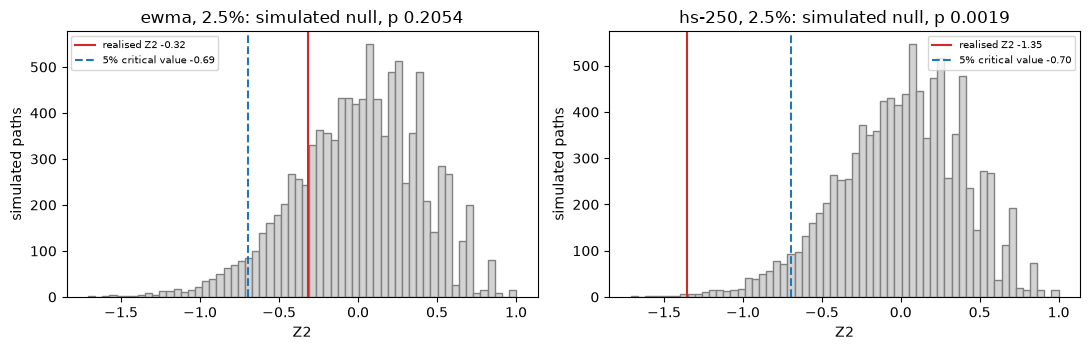

In [4]:
# The tail-consistent null of the pipeline given to the engine's Acerbi-Szekely test, for four models at
# both levels
from pipeline.cases.c11.documents import tail_null
from riskvalidation.validation.market import acerbi_szekely

nulls = {}
print(f"{'model':11s} {'alpha':>6s} {'Z2':>9s} {'p':>9s} {'crit 5%':>9s}")
for mid in ("hs-250", "ewma", "garch-t", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        draws = []
        simulate = tail_null(var, es, alpha, draws)
        result = acerbi_szekely(loss, var, es, alpha, simulate, model_id=mid, statistic="Z2", n_sim=10000, seed=42)
        nulls[(mid, alpha)] = (np.array(draws), result)
        critical = result.extras["critical_5pct"]
        print(f"{mid:11s} {alpha:6.3f} {result.statistic:9.4f} {result.p_value:9.6f} {critical:9.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, mid in zip(axes, ("ewma", "hs-250")):
    draws, result = nulls[(mid, 0.025)]
    ax.hist(draws, bins=60, color="lightgrey", edgecolor="grey")
    ax.axvline(result.statistic, color="tab:red", label=f"realised Z2 {result.statistic:.2f}")
    critical = result.extras["critical_5pct"]
    ax.axvline(critical, color="tab:blue", linestyle="--", label=f"5% critical value {critical:.2f}")
    ax.set_title(f"{mid}, 2.5%: simulated null, p {result.p_value:.4f}")
    ax.set_xlabel("Z2")
    ax.set_ylabel("simulated paths")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Each histogram is the engine's own simulated null of $Z_2$ at 2.5 percent, 10,000 paths drawn from the model's VaR and ES, centred near zero as the construction demands. The realised $Z_2$ of `ewma` (-0.3160) falls inside the bulk of its null and its p-value is 0.205379, while that of `hs-250` (-1.3513) falls far into the left tail, below the 5 percent critical value of -0.6950, with a p-value of 0.001900. The table shows the same split at 1 percent: `ewma` and `garch-t` are not rejected (p 0.255774 and 0.308069) and `hs-250` and `dn-rolling` are, the latter at the floor of 0.000100, the smallest p-value that 10,000 draws can give. The figure shows where a realised value falls in a null built on a stated assumption about the tail; it does not test that assumption.

### Step 3: the critical value belongs to the model, and the published thresholds are a reference point

The published suggestion for $Z_2$ is a yellow zone below $-0.70$ and a red zone below $-1.8$, for $T = 250$ days at $\alpha = 2.5$ percent (Acerbi and Szekely; verified here only through the secondary source of Moldenhauer and Pitera, 2017, section 6). The engine keeps them in `extras["reference"]` and says they are a published reference point, not a threshold. The simulated values show why: the 5 percent and 0.01 percent critical values depend on the model's VaR and ES path, because the simulated excess scales with $\mathrm{ES}_t - \mathrm{VaR}_t$ and the statistic divides by $\mathrm{ES}_t$. The cell lists, for the models with an ES in `fx-2008`, the range of the critical values the engine simulates at each level and draws the realised $Z_2$ of each model against its 5 percent critical value and the reference. The light compares the p-value with 5 percent (amber) and 0.01 percent (red), the engine's defaults.

alpha 0.01: 5% critical value from -1.211 to -1.056 | 0.01% from -3.587 to -2.854
alpha 0.025: 5% critical value from -0.723 to -0.687 | 0.01% from -1.762 to -1.559
published reference (T = 250, alpha = 0.025): {'yellow': -0.7, 'red': -1.8}


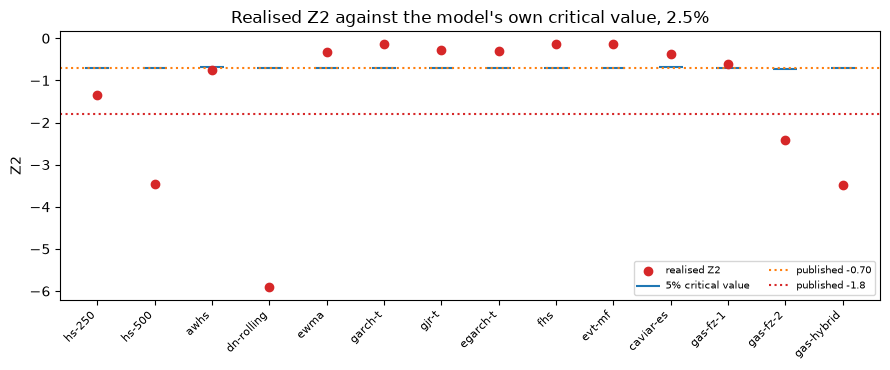

In [5]:
# Simulated Z2 critical values of the 14 models with an ES at both levels, against the published reference point
reference = {"yellow": -0.70, "red": -1.8}
table = {}
for alpha in (0.01, 0.025):
    rows = []
    for mid in with_es:
        level = [lv for lv in models[mid]["by_level"] if lv["alpha"] == alpha][0]
        var, es = np.array(level["var"]), np.array(level["es"])
        simulate = tail_null(var, es, alpha, [])
        result = acerbi_szekely(loss, var, es, alpha, simulate, model_id=mid, statistic="Z2", n_sim=10000, seed=42)
        extras = result.extras
        rows.append((result.statistic, extras["critical_5pct"], extras["critical_0_01pct"], result.p_value))
    table[alpha] = np.array(rows)
    print(f"alpha {alpha}: 5% critical value from {table[alpha][:, 1].min():.3f} to {table[alpha][:, 1].max():.3f}"
          f" | 0.01% from {table[alpha][:, 2].min():.3f} to {table[alpha][:, 2].max():.3f}")
print(f"published reference (T = 250, alpha = 0.025): {reference}")

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(with_es))
ax.scatter(x, table[0.025][:, 0], color="tab:red", zorder=3, label="realised Z2")
ax.scatter(x, table[0.025][:, 1], marker="_", s=300, color="tab:blue", label="5% critical value")
ax.axhline(reference["yellow"], color="tab:orange", linestyle=":", label="published -0.70")
ax.axhline(reference["red"], color="tab:red", linestyle=":", label="published -1.8")
ax.set_xticks(x, with_es, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Z2")
ax.set_title("Realised Z2 against the model's own critical value, 2.5%")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

The blue marks are the 5 percent critical values of the 14 models at 2.5 percent and they sit almost on the published $-0.70$, between -0.723 and -0.687, so for this level and sample size the reference is a fair summary. At 1 percent the critical values are -1.211 to -1.056, far from the reference, and the 0.01 percent values run from -3.587 to -2.854 at 1 percent and from -1.762 to -1.559 at 2.5 percent, less negative than the published $-1.8$. The red dots show the verdict: five models, `hs-250`, `hs-500`, `dn-rolling`, `gas-fz-2` and `gas-hybrid`, fall well below their critical value and the others lie above it. The figure shows that the published pair is a reference for one level and one sample size, and that the engine's critical values depend on the model's own VaR and ES path.

### Step 4: Du-Escanciano, a test built on the whole tail

$Z_2$ looks only at the exceedance days. Du and Escanciano (2017) use the **probability integral transform** (PIT) $u_t = F_t(y_t)$, the position of the realised return in the model's predictive distribution, which is uniform if the distribution is right. The cumulative violation process $H_t(lpha) = \frac{1}{\alpha}(\alpha - u_t)\,\mathbb 1\{u_t \le \alpha\}$ measures how deep into the $\alpha$-tail the observation fell: it is 0 outside the tail and grows to 1 at the extreme. Under correct forecasts $E[H_t] = \alpha/2$ and $\mathrm{Var}(H_t) = \alpha(1/3 - \alpha/4)$, which gives

$$U_{ES} = \frac{\sqrt{T}\,(\bar H - \alpha/2)}{\sqrt{\alpha(1/3-\alpha/4)}} \xrightarrow{d} N(0,1), \qquad C_{ES}(m) = T\sum_{j=1}^{m}\hat\rho_j^{\,2} \xrightarrow{d} \chi^2_m$$

where $\hat\rho_j$ are the autocorrelations of $H_t - \alpha/2$: the first statistic tests the level of the tail, the second whether tail violations come in sequences. Both need a predictive distribution, so the notebook uses two models whose distribution is a normal that the committed forecasts pin down. `ewma` has zero mean and a volatility the committed VaR fixes (step 4 of notebook 02). For `dn-rolling` the mean $\mu$ and volatility $\sigma$ are the two unknowns of the two delta-normal formulas $v = \mu + z\sigma$ and $e = \mu - \sigma\varphi(z)/\alpha$, which the cell inverts per day. The plain asymptotic tests ignore the uncertainty of the estimated parameters, as the engine's notes say. The committed C11 battery does not run these tests, so there are no committed rows to compare with.

ewma       alpha 0.010 | U_ES   1.131 p 0.1291 green
           C_ES(5) p 0.0267 red
ewma       alpha 0.025 | U_ES   0.434 p 0.3323 green
           C_ES(5) p 0.0062 red
dn-rolling alpha 0.010 | U_ES  18.909 p 0.0000 red
           C_ES(5) p 0.1283 green
dn-rolling alpha 0.025 | U_ES  14.780 p 0.0000 red
           C_ES(5) p 0.0634 amber


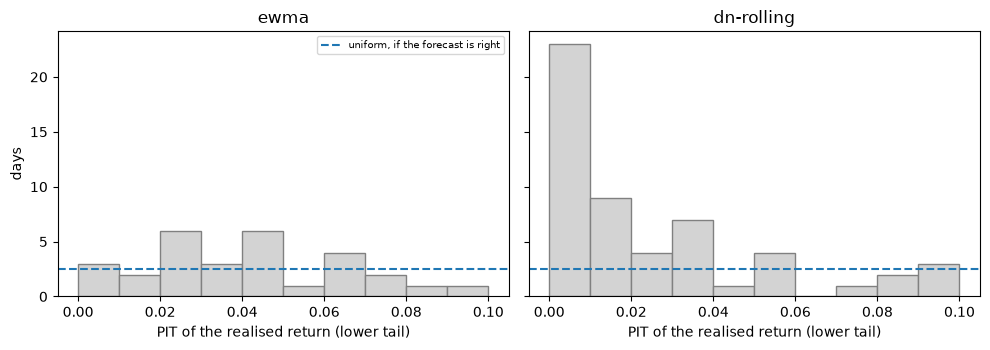

In [6]:
# The predictive normal of ewma and dn-rolling from the committed VaR and ES, the PITs and the Du-Escanciano
# tests
from riskvalidation.validation.market import du_escanciano_conditional, du_escanciano_unconditional

returns = -loss
pits = {}
for mid in ("ewma", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        z = stats.norm.ppf(alpha)
        sigma = var / -z if mid == "ewma" else (es - var) / (stats.norm.pdf(z) / alpha + z)
        mu = np.zeros_like(sigma) if mid == "ewma" else -var - z * sigma
        pit = stats.norm.cdf((returns - mu) / sigma)
        pits[(mid, alpha)] = (pit, sigma)
        unconditional = du_escanciano_unconditional(pit, alpha, model_id=mid)
        conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id=mid)
        print(f"{mid:10s} alpha {alpha:5.3f} | U_ES {unconditional.statistic:7.3f} p {unconditional.p_value:.4f} "
              f"{LIGHT[unconditional.light.value]}")
        print(f"{'':10s} C_ES(5) p {conditional.p_value:.4f} {LIGHT[conditional.light.value]}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, mid in zip(axes, ("ewma", "dn-rolling")):
    ax.hist(pits[(mid, 0.01)][0], bins=np.linspace(0, 0.1, 11), color="lightgrey", edgecolor="grey")
    ax.axhline(0.01 * loss.size, color="tab:blue", linestyle="--", label="uniform, if the forecast is right")
    ax.set_xlabel("PIT of the realised return (lower tail)")
    ax.set_title(mid)
axes[0].set_ylabel("days")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

Each histogram shows where the realised returns fell in the lower 10 percent of the model's own predictive distribution; under a right forecast the bars would be flat at the dashed line, 2.51 days per bin. For `dn-rolling` 23 days fall in the first bin, the 23 exceedances of the 1 percent level, and the unconditional statistic is 18.909 (p 0.0000, red): the level of the tail is wrong. For `ewma` the first bin holds 3 days, close to the dashed line, and $U_{ES}$ does not reject (1.131, p 0.1291), but the conditional test does (p 0.0267 at 1 percent and 0.0062 at 2.5 percent): the days that land deep in the tail come in sequences, which $Z_2$, built on the exceedance days alone, cannot see. The figure shows the whole tail and not only the exceedance days; it does not show the order in time, which only the conditional statistic reads.

### Step 5: McNeil-Frey, the size of the excess over the ES

McNeil and Frey (2000) look at the exceedance days and ask whether the excess over the ES, scaled by the day's volatility, is zero on average: $r_t = (L_t - \mathrm{ES}_t)/\sigma_t$ should be independent with mean zero when the ES is right, and a positive mean means the ES is too low. The engine's `mcneil_frey_residual_test` takes the losses, VaR, ES and $\sigma_t$, and tests a zero mean with a one-sided bootstrap: the residuals centred at their mean are resampled and $p = (1 + \#\{\bar r^* \ge \bar r\})/(n_{boot}+1)$. It is a test of the **size** of the losses beyond the VaR that needs few assumptions, and it needs at least two exceedances. We run it with the $\sigma_t$ of step 4.

ewma       alpha 0.010 | exceedances  3 | mean residual  0.331 | p 0.0374 | red
ewma       alpha 0.025 | exceedances  8 | mean residual  0.075 | p 0.3325 | green
dn-rolling alpha 0.010 | exceedances 23 | mean residual  0.648 | p 0.0002 | red
dn-rolling alpha 0.025 | exceedances 35 | mean residual  0.557 | p 0.0001 | red


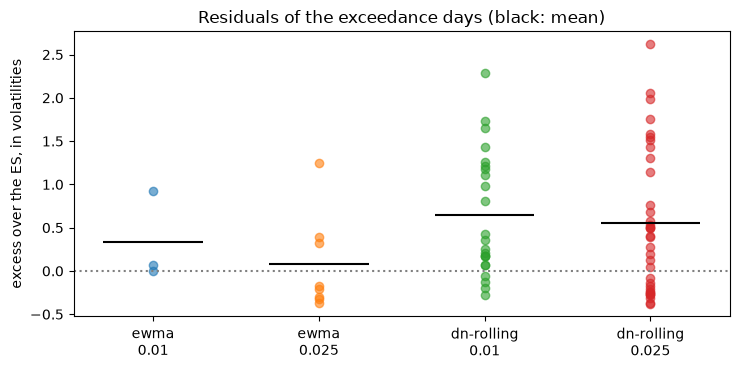

In [7]:
# The McNeil-Frey residual test on the exceedance days of the same two models, with the sigma of the
# previous step
from riskvalidation.validation.market import mcneil_frey_residual_test

residuals = {}
for mid in ("ewma", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        sigma = pits[(mid, alpha)][1]
        result = mcneil_frey_residual_test(loss, var, es, sigma, alpha, model_id=mid, n_boot=10000, seed=0)
        exceed = loss > var
        residuals[(mid, alpha)] = (loss[exceed] - es[exceed]) / sigma[exceed]
        print(f"{mid:10s} alpha {alpha:5.3f} | exceedances {result.n_events:2d} | "
              f"mean residual {result.statistic:6.3f} | p {result.p_value:.4f} | {LIGHT[result.light.value]}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for position, values in enumerate(residuals.values()):
    ax.scatter(np.full(values.size, position), values, alpha=0.6)
    ax.hlines(values.mean(), position - 0.3, position + 0.3, color="black")
ax.axhline(0, color="grey", linestyle=":")
ax.set_xticks(range(len(residuals)), [f"{m}\n{a}" for m, a in residuals])
ax.set_ylabel("excess over the ES, in volatilities")
ax.set_title("Residuals of the exceedance days (black: mean)")
fig.tight_layout()
plt.show()

Each dot is the excess of an exceedance day over the forecast ES, in units of that day's volatility, and the black bar is the mean; a right ES would put the mean at zero. For `dn-rolling` the mean is 0.648 over 23 exceedances at 1 percent (bootstrap p 0.0002) and 0.557 over 35 at 2.5 percent: the losses beyond the VaR are about half a daily volatility above the ES it forecast, and almost every dot is above zero. For `ewma` at 1 percent the mean of 0.331 is red (p 0.0374) but rests on only 3 residuals, while at 2.5 percent the mean is 0.075 over 8 and the test is green (p 0.3325). The figure shows the size of the excess that $Z_2$ folds into one number; with so few exceedances a red light on three residuals is a hint, not a verdict.

### Step 6: the same tests on a second window

A result on one window is an anecdote. The cell runs the Acerbi-Szekely, Du-Escanciano and McNeil-Frey tests for `ewma` in `rates-2022`, where the same model is available in the same way. The point is the contrast between tests: on a given forecast they can disagree, and the validator reads them together.

In [8]:
# ewma in rates-2022: the Acerbi-Szekely, Du-Escanciano and McNeil-Frey tests on the same forecast
rates = docs["rates-2022"]["outputs"]
rates_loss = np.array(rates["grid"]["realised_loss"]["loss"])
ewma_rates = {m["model_id"]: m for m in rates["models"]}["ewma"]
for level in ewma_rates["by_level"]:
    alpha = level["alpha"]
    var, es = np.array(level["var"]), np.array(level["es"])
    sigma = var / -stats.norm.ppf(alpha)
    pit = stats.norm.cdf(-rates_loss / sigma)
    simulate = tail_null(var, es, alpha, [])
    z2 = acerbi_szekely(rates_loss, var, es, alpha, simulate, model_id="ewma", statistic="Z2", n_sim=10000, seed=42)
    unconditional = du_escanciano_unconditional(pit, alpha, model_id="ewma")
    conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id="ewma")
    residual = mcneil_frey_residual_test(rates_loss, var, es, sigma, alpha, model_id="ewma", n_boot=10000, seed=0)
    print(f"alpha {alpha:5.3f} | exceedances {int((rates_loss > var).sum())} | "
          f"Z2 {z2.statistic:.4f} p {z2.p_value:.4f}")
    print(f"  U_ES p {unconditional.p_value:.4f} | C_ES p {conditional.p_value:.4f}")
    print(f"  McNeil-Frey p {residual.p_value:.4f}")

alpha 0.010 | exceedances 6 | Z2 -1.5073 p 0.0183
  U_ES p 0.0307 | C_ES p 0.7818
  McNeil-Frey p 0.2841
alpha 0.025 | exceedances 9 | Z2 -0.5913 p 0.0779
  U_ES p 0.0254 | C_ES p 0.4295
  McNeil-Frey p 0.0993


## Results

**Answer:** Which test sees the failure depends on the failure. `dn-rolling` fails all three: $Z_2$ of -10.4033 (p 0.0001), an unconditional Du-Escanciano statistic of 18.909 and a mean McNeil-Frey excess of 0.648 volatilities over 23 exceedances (p 0.0002). `ewma` passes the $Z_2$ test at both levels (p 0.255774 and 0.205379) yet the conditional Du-Escanciano test rejects it at both (p 0.0267 and 0.0062): the deep-tail days of its ES come in sequences that $Z_2$ cannot see.

- **Z1 and Z2 by hand.** 14 of the 17 models forecast an ES; the other three (`cf-rolling`, `caviar-sav`, `caviar-as`) cannot be tested. `hs-250` at 1 percent has $Z_1 = -0.0691$ and $Z_2 = -3.2592$ with 10 exceedances; `dn-rolling` has $Z_1 = -0.2444$ and $Z_2 = -10.4033$ with 23.
- **The null.** With the pipeline's tail-consistent null, 10,000 draws and seed 42 the engine gives `hs-250` at 1 percent a p-value of 0.000200 and a 5 percent critical value of -1.0906, and `ewma` 0.255774 and -1.1035. The smallest p-value a run can give is 0.0001, which is what the red `dn-rolling` rows show.
- **A critical value per model.** At 2.5 percent the 5 percent critical value runs from -0.723 to -0.687 across the 14 models and the published -0.70 lies inside that range; the 0.01 percent value runs from -1.762 to -1.559, less negative than the published -1.8. At 1 percent the values are far from the reference: -1.211 to -1.056 at 5 percent and -3.587 to -2.854 at 0.01 percent.
- **Du-Escanciano.** For `ewma` the unconditional test does not reject (p 0.1291 at 1 percent and 0.3323 at 2.5 percent) but the conditional test does (p 0.0267 and 0.0062). For `dn-rolling` the level is wrong: $U_{ES}$ is 18.909 at 1 percent and 14.780 at 2.5 percent.
- **McNeil-Frey.** `dn-rolling` has a mean standardised excess of 0.648 over 23 exceedances at 1 percent and 0.557 over 35 at 2.5 percent; `ewma` at 1 percent is red (0.331, p 0.0374) with only 3 exceedances.
- **A second window.** For `ewma` in `rates-2022`, $Z_2$ is -1.5073 and -0.5913 (p 0.0183 and 0.0779), yet the unconditional Du-Escanciano test is red at both levels (p 0.0307 and 0.0254). The tests are not redundant.

What this notebook does not show: how to choose between models that pass all of them (notebook 05).

## Summary

- A VaR back-test counts exceedances; an ES back-test must look at the size of the losses beyond the VaR. $Z_1$ does so on the exceedance days, $Z_2$ also penalises a wrong number of them, and both are zero under correct forecasts and negative when risk is underestimated.
- A critical value needs a null. The engine asks the caller for it; Contraste supplies one tail-consistent null for every rung (an exponential excess with mean $\mathrm{ES} - \mathrm{VaR}$), so each model's critical values come from its own VaR and ES path, under a stated assumption about the shape of the tail.
- The published $-0.70$ and $-1.8$ are a reference point for $T = 250$ and $\alpha = 2.5$ percent, verified only through a secondary source; the simulated critical values differ by model and level.
- Du-Escanciano uses the whole predictive distribution through the PIT, McNeil-Frey the size of the excess over the ES; they need a predictive distribution or a volatility, and on one forecast they can disagree with $Z_2$.
- None of these tests replaces the count tests of notebook 03; the eligibility gates of the ladder use Kupiec, conditional coverage and $Z_2$ together.

**What to try next.** Change `n_sim` in step 2 to 1000 and watch the p-value and the 0.01 percent critical value, which needs at least 10,000 draws to resolve; then read notebook 05, which ranks the models that pass.

## References

- Acerbi, C. and Szekely, B. (2014), Backtesting expected shortfall, Risk, December 2014 (primary text not retrieved). The reference point of -0.70 and -1.8 is read through Moldenhauer, G. and Pitera, M. (2017), Backtesting expected shortfall, section 6. https://arxiv.org/abs/1709.01337
- Du, Z. and Escanciano, J. C. (2017), Backtesting expected shortfall: accounting for tail risk, Management Science 63(4). https://doi.org/10.1287/mnsc.2015.2342
- McNeil, A. J. and Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Nolde, N. and Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041